# SwinV2-Small — Swin Transformer V2 (ImageNet-22k)

**EEEM068 Applied Machine Learning — Group Coursework**

**Model:** `swinv2_small_window8_256` pre-trained on ImageNet-22k, fine-tuned for 5-class DR grading.

**Why SwinV2 over V1:**
- Post-normalisation + scaled cosine attention → stable fine-tuning, no activation collapse
- Log-CPB continuous position bias → smooth transfer between resolutions
- Lower GPU memory than SwinV1-Base at same accuracy level

**Notebook structure mirrors `vit_b16.ipynb` for direct group comparison.**

| Section | Content |
|---|---|
| 1–9 | Baseline: SwinV2 + CrossEntropyLoss, no imbalance handling |
| 10 | Evaluation on test set |
| 11 | **Exp 1** — Class imbalance: WeightedRandomSampler + FocalLoss |
| 12 | **Exp 2** — Enhanced augmentation |
| 13 | **Exp 3** — Two-phase training (freeze → unfreeze) |
| 14 | **Exp 4** — Hyperparameter search (LR × weight decay) |
| 15 | **Exp 5** — Majority-class downsampling |

## 1. Imports

In [1]:
import os
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix,
    f1_score, accuracy_score, precision_score, recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch : 2.11.0+cu130
timm    : 1.0.26
CUDA    : True


## 2. Configuration

In [2]:
# ── Paths ─────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'        # 13-stage preprocessed images
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR     = ROOT / 'outputs' / 'swinv2_small'
CKPT_DIR    = OUT_DIR / 'checkpoints'
FIGURES_DIR = OUT_DIR / 'figures'
for d in (OUT_DIR, CKPT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Experiment ────────────────────────────────────────────────
EXPERIMENT_NAME = 'swinv2_small'
MODEL_NAME      = 'swinv2_small_window8_256'

# ── Offline weights (Surrey HPC — compute nodes have no internet) ─────────────
# Download once on the LOGIN NODE:
#   mkdir -p /scratch/AML_G14_CW/weights/
#   wget -O /scratch/AML_G14_CW/weights/swinv2_small.safetensors \
#     https://huggingface.co/timm/swinv2_small_window8_256.ms_in1k/resolve/main/model.safetensors
WEIGHTS_PATH = ROOT / 'weights' / 'swinv2_small.safetensors'
# Set to None to download from HuggingFace (requires internet)

# ── Reproducibility ───────────────────────────────────────────
SEED = 42

# ── Data ──────────────────────────────────────────────────────
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

# ── Image ─────────────────────────────────────────────────────
# SwinV2-Small native pre-training resolution — do NOT change
IMAGE_SIZE = 256
# ImageNet mean/std — required for SwinV2 pretrained on ImageNet-22k
# (ViT uses 0.5/0.5/0.5 — different model, different normalisation)
SWIN_MEAN = (0.485, 0.456, 0.406)
SWIN_STD  = (0.229, 0.224, 0.225)

# ── Training ──────────────────────────────────────────────────
# VRAM guide: 8 GB → BATCH_SIZE=8 | 16 GB → 16 | 40 GB (A100) → 32
BATCH_SIZE             = 16
EPOCHS                 = 35
LR                     = 3e-5
WEIGHT_DECAY           = 3e-2
NUM_WORKERS            = 4
EARLY_STOPPING_PATIENCE = 10
DROPOUT                = 0.3

In [3]:
# ── Seed + device ─────────────────────────────────────────────
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

Device: cuda
GPU   : NVIDIA RTX A4000
VRAM  : 16.7 GB


In [4]:
# ── Checkpoint registry — run this cell to resume eval after kernel restart ───
CKPT_BASELINE = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
CKPT_EXP1     = ROOT / 'outputs' / 'swinv2_small_exp1' / 'checkpoints' / 'swinv2_small_exp1_best.pt'
CKPT_EXP2     = ROOT / 'outputs' / 'swinv2_small_exp2' / 'checkpoints' / 'swinv2_small_exp2_best.pt'
CKPT_EXP3_P1  = ROOT / 'outputs' / 'swinv2_small_exp3' / 'checkpoints' / 'swinv2_small_exp3_phase1_best.pt'
CKPT_EXP3     = ROOT / 'outputs' / 'swinv2_small_exp3' / 'checkpoints' / 'swinv2_small_exp3_best.pt'
CKPT_EXP5     = ROOT / 'outputs' / 'swinv2_small_exp5' / 'checkpoints' / 'swinv2_small_exp5_best.pt'

print('Checkpoint registry:')
for label, path in [
    ('Baseline', CKPT_BASELINE),
    ('Exp1',     CKPT_EXP1),
    ('Exp2',     CKPT_EXP2),
    ('Exp3-P1',  CKPT_EXP3_P1),
    ('Exp3',     CKPT_EXP3),
    ('Exp5',     CKPT_EXP5),
]:
    status = '✓' if path.exists() else '–'
    print(f'  [{status}] {label:<10}: {path.name}')

Checkpoint registry:
  [✓] Baseline  : swinv2_small_best.pt
  [✓] Exp1      : swinv2_small_exp1_best.pt
  [✓] Exp2      : swinv2_small_exp2_best.pt
  [✓] Exp3-P1   : swinv2_small_exp3_phase1_best.pt
  [✓] Exp3      : swinv2_small_exp3_best.pt
  [✓] Exp5      : swinv2_small_exp5_best.pt


## 3. Load Pre-Split Data

In [5]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images  (dir: train_proc/)')
print(f'Val   : {len(val_df):,} images   (dir: val_proc/)')
print(f'Test  : {len(test_df):,} images   (dir: test_labels_proc/)')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')
print()
max_c = train_df['level'].value_counts().max()
min_c = train_df['level'].value_counts().min()
print(f'Imbalance ratio (train): {max_c/min_c:.1f}×')

Train : 24,588 images  (dir: train_proc/)
Val   : 5,269 images   (dir: val_proc/)
Test  : 5,269 images   (dir: test_labels_proc/)

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106

Imbalance ratio (train): 36.4×


## 4. Dataset and DataLoaders

In [6]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads pre-processed images from data_dir.

    Images are loaded from train_proc/ / val_proc/ / test_labels_proc/ —
    the 13-stage preprocessing (Ben Graham + CLAHE + circular mask etc.)
    has already been applied by data_preprocessing.ipynb.
    No on-the-fly preprocessing needed here; only augmentation transforms.
    """

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ── Baseline transforms ────────────────────────────────────────
# SwinV2 requires ImageNet mean/std normalisation (not 0.5/0.5/0.5 like ViT)
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(SWIN_MEAN, SWIN_STD),
])

val_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.05)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(SWIN_MEAN, SWIN_STD),
])

train_ds = DRDataset(train_df, TRAIN_DIR, transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}')

Train batches: 1536 | Val batches: 330 | Test batches: 330


## 5. Model

`swinv2_small_window8_256` — pre-trained on ImageNet-22k (11,821 classes).

**Why SwinV2-Small over Base:**
- Only 0.5% ImageNet accuracy gap vs Base, but 38M fewer params (50M vs 88M)
- Fits comfortably on 16 GB GPU at batch=16; Base risks OOM
- Over-parameterisation increases overfitting risk on ~25k training images

**Head design:**
Custom head replaces timm's internal head to avoid a SwinV2-specific bug
where `forward_features()` returns `(B, tokens, C)` — a 3D tensor — which
causes `CrossEntropyLoss` to raise a shape error. Using `backbone.forward`
(which applies Global Average Pooling internally) returns `(B, C)` instead.

In [7]:
def _load_swin_weights(backbone: nn.Module, weights_path: str) -> None:
    """Load local .safetensors with strict=False.

    Safely ignores:
      - head.fc.weight / head.fc.bias  (original ImageNet head — we replace it)
      - layers.*.attn_mask             (cached buffers, recomputed at runtime)
    All feature extraction weights (patch embed, attention, MLP) are loaded.
    """
    from timm.models._helpers import load_checkpoint
    result = load_checkpoint(backbone, weights_path, strict=False)
    n_head = len([k for k in result.missing_keys    if 'custom_head' in k])
    n_skip = len([k for k in result.unexpected_keys if 'head.fc' in k or 'attn_mask' in k])
    print(f'  Weights loaded — head keys (random init): {n_head}, old keys ignored: {n_skip}')


def build_swin_model(pretrained: bool = True) -> nn.Module:
    """Build SwinV2-Small with a custom 5-class classification head.

    IMPORTANT — why custom_head + _base_forward:
      timm's SwinV2 forward_features() returns (B, tokens, C).
      Attaching a Linear head directly would produce (B, tokens, 5),
      causing CrossEntropyLoss to raise 'only batches of spatial targets
      supported'. Using backbone.forward (which includes GAP pooling)
      returns (B, 768) — the correct 2D shape for classification.
    """
    backbone = timm.create_model(
        MODEL_NAME,
        pretrained  = False,   # always False here — we handle weights below
        num_classes = 0,       # remove timm head
        global_pool = 'avg',
    )
    feat_dim = backbone.num_features   # 768 for SwinV2-Small

    # Attach head BEFORE loading weights so old keys are correctly labelled unexpected
    backbone.custom_head = nn.Sequential(
        nn.LayerNorm(feat_dim),
        nn.Dropout(p=DROPOUT),
        nn.Linear(feat_dim, NUM_CLASSES),
    )
    _base_forward = backbone.forward   # includes GAP → returns (B, 768)
    backbone.forward = lambda x: backbone.custom_head(_base_forward(x))

    # Load weights: local file → HuggingFace download → random init
    wp = Path(str(WEIGHTS_PATH)) if WEIGHTS_PATH else None
    if wp and wp.exists():
        print(f'Loading weights from local file: {wp}')
        _load_swin_weights(backbone, str(wp))
        print('Local pretrained weights loaded.')
    elif pretrained:
        try:
            print('Downloading pretrained weights from HuggingFace...')
            tmp = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0, global_pool='avg')
            own_sd = backbone.state_dict()
            src_sd = {k: v for k, v in tmp.state_dict().items()
                      if k in own_sd and 'custom_head' not in k}
            own_sd.update(src_sd)
            backbone.load_state_dict(own_sd, strict=False)
            del tmp
            print('Downloaded and loaded pretrained weights.')
        except Exception as e:
            print(f'Download failed: {e}')
            print('Set WEIGHTS_PATH in config cell or set pretrained=False.')
            raise
    else:
        print('pretrained=False — random initialisation (scratch experiment).')

    total = sum(p.numel() for p in backbone.parameters()) / 1e6
    print(f'SwinV2-Small | {total:.1f}M params | feat_dim={feat_dim}')
    return backbone


model = build_swin_model(pretrained=True).to(device)

Downloaded and loaded pretrained weights.
SwinV2-Small | 49.0M params | feat_dim=768


## 6. Loss, Optimiser, Scheduler

Baseline: standard `CrossEntropyLoss` with label smoothing, no class weights.
Layer-wise LR decay: backbone gets 0.1× LR, head gets full LR — prevents
catastrophic forgetting of ImageNet-22k pre-trained representations.

In [8]:
# Layer-wise LR: backbone gets 0.1× LR, head gets full LR
# This is specific to Swin transformers — ViT uses uniform LR
backbone_params = [p for n, p in model.named_parameters()
                   if 'custom_head' not in n and p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if 'custom_head' in n and p.requires_grad]

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    [{'params': backbone_params, 'lr': LR * 0.1},
     {'params': head_params,     'lr': LR}],
    weight_decay=WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print('Loss      :', criterion)
print('Optimiser : AdamW  (backbone lr={:.1e}, head lr={:.1e})'.format(LR*0.1, LR))
print('Scheduler :', scheduler.__class__.__name__)

Loss      : CrossEntropyLoss()
Optimiser : AdamW  (backbone lr=3.0e-06, head lr=3.0e-05)
Scheduler : CosineAnnealingLR


## 7. Training Loop

In [9]:
use_amp = device.type == 'cuda'
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)


def run_epoch(loader, train_mode: bool, grad_clip: float = 1.0):
    """Single train or eval pass. Returns (loss, labels, preds, kappa)."""
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False,
                               desc='train' if train_mode else 'val  '):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if grad_clip > 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / total
    kappa    = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
    return avg_loss, all_labels, all_preds, kappa

In [10]:
best_path     = CKPT_BASELINE
best_val_kappa = -1.0
patience_left  = EARLY_STOPPING_PATIENCE

history = {'train_loss': [], 'val_loss': [], 'train_kappa': [], 'val_kappa': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds, tr_kappa = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds, vl_kappa = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_kappa'].append(tr_kappa)
    history['val_kappa'].append(vl_kappa)

    marker = ''
    if vl_kappa > best_val_kappa:
        best_val_kappa = vl_kappa
        patience_left  = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, best_path)
        marker = '  ★'

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

    if not marker:
        patience_left -= 1
        if patience_left <= 0:
            print(f'Early stopping at epoch {epoch}.')
            break

print(f'\nBest val κ = {best_val_kappa:.4f}  →  {best_path.name}')

Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.9858   0.2581     0.9165   0.4287  ★


2            0.9095   0.4988     0.8849   0.5343  ★


3            0.8834   0.5676     0.8632   0.5757  ★


4            0.8586   0.6121     0.8603   0.5814  ★


...

31           0.7211   0.7877     0.8257   0.6996


32           0.7219   0.7882     0.8269   0.6984


33           0.7175   0.7966     0.8245   0.7026


34           0.7199   0.7904     0.8271   0.6988


35           0.7191   0.7882     0.8263   0.7005

Best val κ = 0.7034  →  swinv2_small_best.pt


## 8. Loss + Kappa Curves

In [ ]:
print('\nLoading best model for final evaluation...')
print(ssss
      a

Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────
1            0.9858   0.2581     0.9165   0.4287
2            0.9095   0.4988     0.8849   0.5343
3            0.8834   0.5676     0.8632   0.5757
4            0.8586   0.6121     0.8603   0.5814
5            0.8441   0.6370     0.8753   0.6137
6            0.8320   0.6553     0.8402   0.6444
7            0.8186   0.6727     0.8376   0.6225
8            0.8061   0.6895     0.8349   0.6498
9            0.7993   0.7002     0.8239   0.6668
10           0.7944   0.7076     0.8239   0.6662
11           0.7882   0.7152     0.8470   0.6750
12           0.7797   0.7258     0.8219   0.6894
13           0.7756   0.7365     0.8248   0.6807
14           0.7697   0.7340     0.8276   0.6737
15           0.7647   0.7450     0.8180   0.6793
16           0.7597   0.7467     0.8206   0.6933
17           0.7553   0.7527     0.8149   0.6835
18           0.7514   0.7581     0.8182   0.7020
19           0.7

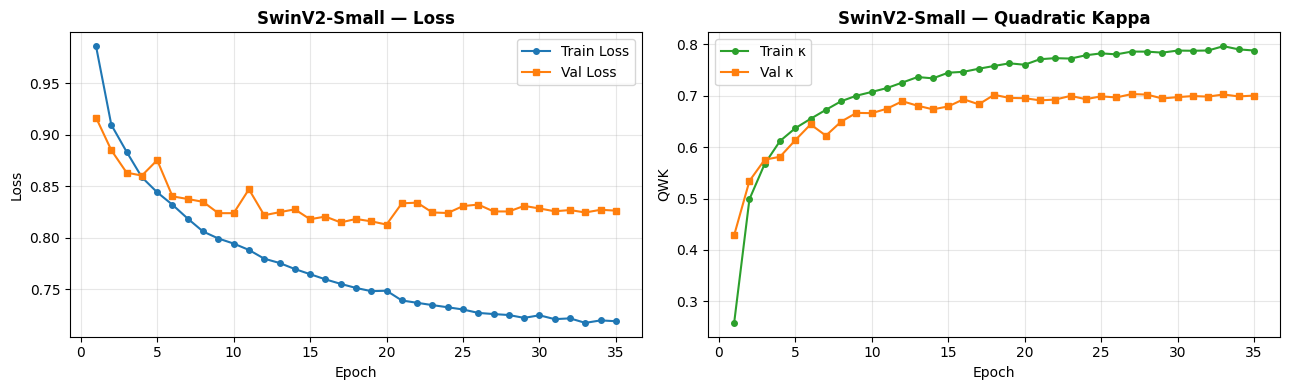

In [11]:
epochs_ran = range(1, len(history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)
for ep, (tl, tk, vl, vk) in enumerate(
    zip(history['train_loss'], history['train_kappa'],
        history['val_loss'],   history['val_kappa']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {tk:>8.4f} {vl:>10.4f} {vk:>8.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=4)
axes[0].plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=4)
axes[0].set_title('SwinV2-Small — Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['train_kappa'], label='Train κ', marker='o', markersize=4, color='tab:green')
axes[1].plot(epochs_ran, history['val_kappa'],   label='Val κ',   marker='s', markersize=4, color='tab:orange')
axes[1].set_title('SwinV2-Small — Quadratic Kappa', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('QWK')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Evaluation on Test Set

In [12]:
# ── Independent of training — run this cell alone after kernel restart ───────
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = build_swin_model(pretrained=False).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

ckpt = torch.load(CKPT_BASELINE, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {CKPT_BASELINE.name}')
print(f'epoch={ckpt["epoch"]}  val_kappa={ckpt["val_kappa"]:.4f}')

_, y_true, y_pred, _ = run_epoch(test_loader, train_mode=False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
print(f'Quadratic Weighted Kappa: {cohen_kappa_score(y_true, y_pred, weights="quadratic"):.4f}')

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion

pretrained=False — random initialisation (scratch experiment).
SwinV2-Small | 49.0M params | feat_dim=768
Loaded: swinv2_small_best.pt
epoch=27  val_kappa=0.7034



Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.864     0.947     0.904      3872
         Mild      0.357     0.014     0.026       366
     Moderate      0.560     0.591     0.575       794
       Severe      0.549     0.344     0.423       131
Proliferative      0.663     0.594     0.627       106

     accuracy                          0.806      5269
    macro avg      0.599     0.498     0.511      5269
 weighted avg      0.771     0.806     0.776      5269

Quadratic Weighted Kappa: 0.7135


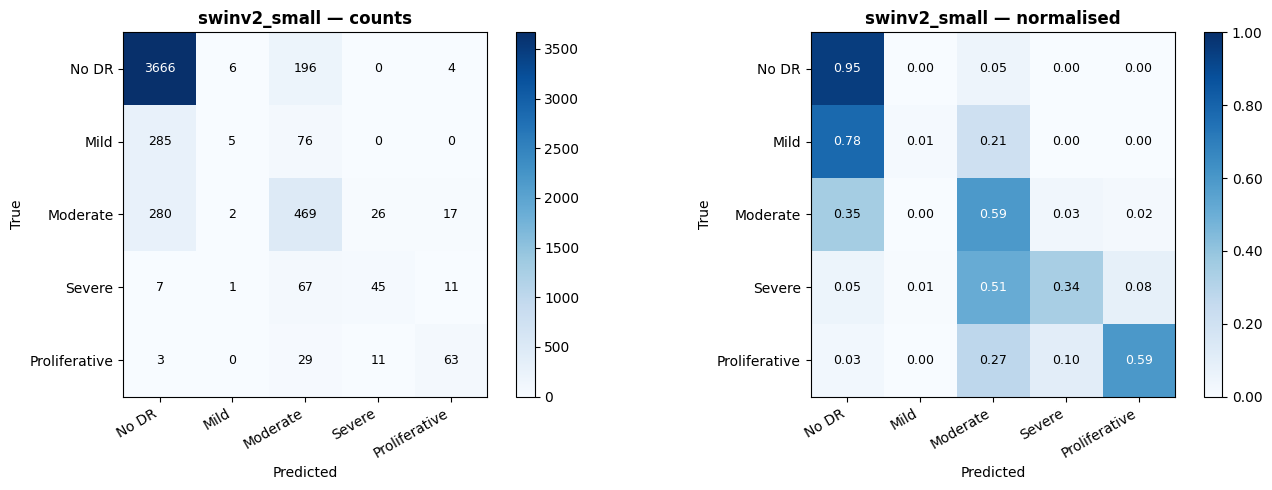

In [13]:
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, fmt, cmap in zip(
    axes,
    [cm, cm.astype(float) / cm.sum(axis=1, keepdims=True)],
    [f'{EXPERIMENT_NAME} — counts', f'{EXPERIMENT_NAME} — normalised'],
    ['d', '.2f'],
    ['Blues', 'Blues'],
):
    im = ax.imshow(data, interpolation='nearest', cmap=cmap,
                   vmin=None if fmt=='d' else 0, vmax=None if fmt=='d' else 1)
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title, fontweight='bold')
    thresh = (data.max() / 2) if fmt=='d' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(data[i,j], fmt), ha='center', va='center', fontsize=9,
                    color='white' if data[i,j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Results Summary

In [14]:
qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
acc    = accuracy_score(y_true, y_pred)
f1_per = f1_score(y_true, y_pred, average=None, labels=list(range(5)))

print('=' * 56)
print('  SwinV2-Small (ImageNet-22k) — TEST SET RESULTS')
print('=' * 56)
print(f'  Test QWK      : {qwk:.4f}')
print(f'  Test Accuracy : {acc:.4f}  (not the primary metric)')
print(f'  Macro F1      : {f1_score(y_true, y_pred, average="macro"):.4f}')
print(f'  Macro Prec.   : {precision_score(y_true, y_pred, average="macro", zero_division=0):.4f}')
print(f'  Macro Recall  : {recall_score(y_true, y_pred, average="macro", zero_division=0):.4f}')
print()
print('  Per-class F1:')
for name, f1 in zip(CLASS_NAMES, f1_per):
    bar = '█' * int(f1 * 20)
    print(f'    {name:<18}: {f1:.4f}  {bar}')
print('=' * 56)

  SwinV2-Small (ImageNet-22k) — TEST SET RESULTS
  Test QWK      : 0.7135
  Test Accuracy : 0.8062  (not the primary metric)
  Macro F1      : 0.5109
  Macro Prec.   : 0.5988
  Macro Recall  : 0.4978

  Per-class F1:
    No DR             : 0.9037  ██████████████████
    Mild              : 0.0263  
    Moderate          : 0.5751  ███████████
    Severe            : 0.4225  ████████
    Proliferative     : 0.6269  ████████████


## 11. Experiment 1 — Class Imbalance Handling

**Hypothesis:** The ~36× class imbalance (Grade 0 = 73.5% vs Grade 4 = 2.0%)
biases the baseline towards the majority class and suppresses minority-class recall.
Combining three complementary techniques should improve QWK — especially on
under-represented grades — without changing the architecture or hyperparameters.

**Techniques (all combined):**
| Technique | Where it acts | What it does |
|---|---|---|
| `WeightedRandomSampler` | Data pipeline | Over-samples minority grades so each epoch sees near-balanced class frequencies |
| `FocalLoss` (γ=2) | Loss function | Down-weights easy majority examples, focuses learning on hard minority cases |
| Inverse-frequency α | Loss function | Per-class weight in Focal Loss — grades 3 and 4 get highest weight |

In [15]:
class FocalLoss(nn.Module):
    """Focal Loss with per-class alpha weighting.

    alpha : Tensor[NUM_CLASSES] — inverse-frequency class weights (on device).
    gamma : focusing parameter; (1-pt)^gamma down-weights easy examples.

    NOTE: Do NOT combine with WeightedRandomSampler AND CLASS_WEIGHTS_AUTO
    simultaneously — the double-weighting collapses grade 0 recall to zero.
    FocalLoss alpha already encodes the class imbalance.
    """
    def __init__(self, alpha: torch.Tensor, gamma: float = 2.0):
        super().__init__()
        self.register_buffer('alpha', alpha)   # moves with .to(device), saved in checkpoint
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        ce = F.cross_entropy(logits, target, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)
        return ((1.0 - pt) ** self.gamma * ce).mean()

print('FocalLoss defined.')

FocalLoss defined.


In [16]:
# ── 1. Inverse-frequency class weights ───────────────────────────────────────
train_labels = train_df['level'].values

class_weights_np = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels,
)
class_weights_t = torch.tensor(class_weights_np, dtype=torch.float32).to(device)

print('Class weights (inverse-frequency, balanced):')
for name, w in zip(CLASS_NAMES, class_weights_np):
    print(f'  {name:<20}: {w:.4f}')

# ── 2. Per-sample weights for WeightedRandomSampler ──────────────────────────
sample_weights_t = torch.as_tensor(class_weights_np[train_labels], dtype=torch.double)

exp1_sampler = WeightedRandomSampler(
    weights=sample_weights_t,
    num_samples=len(sample_weights_t),
    replacement=True,
)

# ── 3. New train loader (sampler replaces shuffle); val/test unchanged ─────────
exp1_train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=exp1_sampler,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
print(f'\nWeightedRandomSampler: {len(exp1_sampler):,} samples/epoch')

Class weights (inverse-frequency, balanced):
  No DR               : 0.2722
  Mild                : 2.8758
  Moderate            : 1.3276
  Severe              : 8.0484
  Proliferative       : 9.9145

WeightedRandomSampler: 24,588 samples/epoch


In [17]:
set_seed(SEED)

exp1_model = build_swin_model(pretrained=True).to(device)

exp1_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)

# Layer-wise LR (same as baseline)
exp1_backbone_p = [p for n, p in exp1_model.named_parameters()
                   if 'custom_head' not in n and p.requires_grad]
exp1_head_p     = [p for n, p in exp1_model.named_parameters()
                   if 'custom_head' in n and p.requires_grad]
exp1_optimizer  = torch.optim.AdamW(
    [{'params': exp1_backbone_p, 'lr': LR * 0.1},
     {'params': exp1_head_p,     'lr': LR}],
    weight_decay=WEIGHT_DECAY,
)
exp1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp1_optimizer, T_max=EPOCHS)
exp1_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP1_OUT_DIR  = ROOT / 'outputs' / 'swinv2_small_exp1'
EXP1_CKPT_DIR = EXP1_OUT_DIR / 'checkpoints'
EXP1_FIG_DIR  = EXP1_OUT_DIR / 'figures'
for d in (EXP1_CKPT_DIR, EXP1_FIG_DIR): d.mkdir(parents=True, exist_ok=True)
EXP1_BEST_PATH = CKPT_EXP1

print('Exp1 model ready.')
print(f'Loss: FocalLoss (gamma=2.0, alpha from inverse-freq weights)')
print(f'Sampler: WeightedRandomSampler')

Downloaded and loaded pretrained weights.
SwinV2-Small | 49.0M params | feat_dim=768
Exp1 model ready.
Loss: FocalLoss (gamma=2.0, alpha from inverse-freq weights)
Sampler: WeightedRandomSampler


In [18]:
_baseline_model     = globals().get('model',     None)
_baseline_criterion = globals().get('criterion', None)
_baseline_optimizer = globals().get('optimizer', None)
_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp1_model, exp1_criterion, exp1_optimizer, exp1_scaler

exp1_best_val_kappa = -1.0
exp1_patience_left  = EARLY_STOPPING_PATIENCE
exp1_history = {'train_loss': [], 'val_loss': [], 'train_kappa': [], 'val_kappa': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds, tr_kappa = run_epoch(exp1_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds, vl_kappa = run_epoch(val_loader,        train_mode=False)
    exp1_scheduler.step()

    exp1_history['train_loss'].append(tr_loss)
    exp1_history['val_loss'].append(vl_loss)
    exp1_history['train_kappa'].append(tr_kappa)
    exp1_history['val_kappa'].append(vl_kappa)

    marker = ''
    if vl_kappa > exp1_best_val_kappa:
        exp1_best_val_kappa = vl_kappa
        exp1_patience_left  = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, EXP1_BEST_PATH)
        marker = '  ★'

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

    if not marker:
        exp1_patience_left -= 1
        if exp1_patience_left <= 0:
            print(f'Early stopping at epoch {epoch}.')
            break

if _baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _baseline_model, _baseline_criterion, _baseline_optimizer, _baseline_scaler)
print(f'\nExp1 best val κ = {exp1_best_val_kappa:.4f}')

Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            3.5707   0.4882     1.2003   0.2059  ★


KeyboardInterrupt: 

In [ ]:
# ── Loss + kappa curves ───────────────────────────────────────────────────────
epochs_ran_exp1 = range(1, len(exp1_history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, key_tr, key_vl, title, ylabel in [
    (axes[0], 'train_loss',  'val_loss',  'Exp1 — Loss',  'Loss'),
    (axes[1], 'train_kappa', 'val_kappa', 'Exp1 — Kappa', 'QWK'),
]:
    ax.plot(epochs_ran_exp1, exp1_history[key_tr], label='Train', marker='o', markersize=4)
    ax.plot(epochs_ran_exp1, exp1_history[key_vl], label='Val',   marker='s', markersize=4)
    ax.set_title(f'SwinV2-Small {title}\n(FocalLoss γ=2 + WeightedRandomSampler)', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'swinv2_exp1_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Independent eval — requires Sections 1–6 + checkpoint registry ──────────
_prev_model = globals().get('model', None); _prev_crit = globals().get('criterion', None)

model     = build_swin_model(pretrained=False).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
ckpt = torch.load(CKPT_EXP1, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1: loaded {CKPT_EXP1.name}  (epoch {ckpt["epoch"]}, val_κ={ckpt["val_kappa"]:.4f})')

_, exp1_y_true, exp1_y_pred, _ = run_epoch(test_loader, train_mode=False)
print('\nExp1 Classification Report (Test Set):')
print(classification_report(exp1_y_true, exp1_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None: model, criterion = _prev_model, _prev_crit

In [ ]:
exp1_qwk    = cohen_kappa_score(exp1_y_true, exp1_y_pred, weights='quadratic')
exp1_acc    = accuracy_score(exp1_y_true, exp1_y_pred)
exp1_f1_per = f1_score(exp1_y_true, exp1_y_pred, average=None, labels=list(range(5)))

cm_exp1 = confusion_matrix(exp1_y_true, exp1_y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, fmt, cmap in zip(
    axes,
    [cm_exp1, cm_exp1.astype(float)/cm_exp1.sum(axis=1,keepdims=True)],
    ['Exp1 — counts (WRS + FocalLoss)', 'Exp1 — normalised'],
    ['d', '.2f'], ['Oranges', 'Oranges'],
):
    im = ax.imshow(data, cmap=cmap, vmin=None if fmt=='d' else 0, vmax=None if fmt=='d' else 1)
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title, fontweight='bold')
    thresh = (data.max()/2) if fmt=='d' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(data[i,j], fmt), ha='center', va='center', fontsize=9,
                    color='white' if data[i,j]>thresh else 'black')
plt.tight_layout()
fig.savefig(EXP1_FIG_DIR / 'swinv2_exp1_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

print('=' * 62)
print(f'  {"Metric":<25} {"Baseline":>10}  {"Exp1 (WRS+Focal)":>16}')
print('=' * 62)
arrow = '▲' if exp1_qwk > qwk else '▼'
print(f'  {"Test QWK":<25} {qwk:>10.4f}  {exp1_qwk:>16.4f}  {arrow}')
print(f'  {"Test Accuracy":<25} {acc:>10.4f}  {exp1_acc:>16.4f}')
print()
print('  Per-class F1:')
for name, f1_b, f1_e in zip(CLASS_NAMES, f1_per, exp1_f1_per):
    delta = f1_e - f1_b
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e:.4f}  ({delta:+.4f})')

## 12. Experiment 2 — Enhanced Augmentation

**Hypothesis:** The baseline training transform omits several augmentations that
improve generalisation on retinal images. Adding vertical flip, rotation,
colour jitter, random affine, and random erasing should reduce overfitting
and improve QWK — especially for minority classes with few training examples.

**Additions over Exp 1:**

| Augmentation | Rationale |
|---|---|
| `RandomVerticalFlip(p=0.5)` | Fundus images have no canonical up/down orientation |
| `RandomRotation(30°)` | Rotation-invariance for vessel and lesion patterns |
| `ColorJitter(0.2, 0.2, 0.2, 0.05)` | Handles varying camera and lighting conditions |
| `RandomAffine(translate, scale)` | Mild geometric distortion for fundus shape variation |
| `RandomErasing(p=0.2)` | Forces model to attend to multiple regions, not just optic disc |

In [21]:
exp2_train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(degrees=30)], p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)
    ], p=0.4),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05))
    ], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(SWIN_MEAN, SWIN_STD),
    transforms.RandomErasing(p=0.2),
])

exp2_train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)

# Reuse exp1_sampler (WeightedRandomSampler) — same class-balance strategy
exp2_train_loader = DataLoader(
    exp2_train_ds, batch_size=BATCH_SIZE, sampler=exp1_sampler,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)

set_seed(SEED)
exp2_model     = build_swin_model(pretrained=True).to(device)
exp2_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp2_backbone_p = [p for n,p in exp2_model.named_parameters()
                   if 'custom_head' not in n and p.requires_grad]
exp2_head_p     = [p for n,p in exp2_model.named_parameters()
                   if 'custom_head' in n and p.requires_grad]
exp2_optimizer  = torch.optim.AdamW(
    [{'params': exp2_backbone_p, 'lr': LR*0.1},
     {'params': exp2_head_p,     'lr': LR}],
    weight_decay=WEIGHT_DECAY)
exp2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp2_optimizer, T_max=EPOCHS)
exp2_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP2_OUT_DIR  = ROOT / 'outputs' / 'swinv2_small_exp2'
EXP2_CKPT_DIR = EXP2_OUT_DIR / 'checkpoints'
EXP2_FIG_DIR  = EXP2_OUT_DIR / 'figures'
for d in (EXP2_CKPT_DIR, EXP2_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

print('Exp2 ready — enhanced augmentation + WRS + FocalLoss')

Downloaded and loaded pretrained weights.
SwinV2-Small | 49.0M params | feat_dim=768
Exp2 ready — enhanced augmentation + WRS + FocalLoss


In [ ]:
_e2_baseline_model, _e2_baseline_criterion = globals().get('model'), globals().get('criterion')
_e2_baseline_optimizer, _e2_baseline_scaler = globals().get('optimizer'), globals().get('scaler')

model, criterion, optimizer, scaler = exp2_model, exp2_criterion, exp2_optimizer, exp2_scaler

exp2_history = {'train_loss':[],'val_loss':[],'train_kappa':[],'val_kappa':[]}
exp2_best_val_kappa = -1.0
exp2_patience_left  = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds, tr_kappa = run_epoch(exp2_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds, vl_kappa = run_epoch(val_loader,        train_mode=False)
    exp2_scheduler.step()

    exp2_history['train_loss'].append(tr_loss)
    exp2_history['val_loss'].append(vl_loss)
    exp2_history['train_kappa'].append(tr_kappa)
    exp2_history['val_kappa'].append(vl_kappa)

    marker = ''
    if vl_kappa > exp2_best_val_kappa:
        exp2_best_val_kappa = vl_kappa
        exp2_patience_left  = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, CKPT_EXP2)
        marker = '  ★'

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

    if not marker:
        exp2_patience_left -= 1
        if exp2_patience_left <= 0:
            print(f'Early stopping at epoch {epoch}.'); break

if _e2_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e2_baseline_model, _e2_baseline_criterion, _e2_baseline_optimizer, _e2_baseline_scaler)
print(f'\nExp2 best val κ = {exp2_best_val_kappa:.4f}')

In [ ]:
# ── Independent eval ─────────────────────────────────────────────────────────
_prev_model = globals().get('model'); _prev_crit = globals().get('criterion')
model = build_swin_model(pretrained=False).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
ckpt = torch.load(CKPT_EXP2, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp2: loaded (epoch {ckpt["epoch"]}, val_κ={ckpt["val_kappa"]:.4f})')
_, exp2_y_true, exp2_y_pred, _ = run_epoch(test_loader, train_mode=False)
print(classification_report(exp2_y_true, exp2_y_pred, target_names=CLASS_NAMES, digits=3))
if _prev_model is not None: model, criterion = _prev_model, _prev_crit

exp2_qwk    = cohen_kappa_score(exp2_y_true, exp2_y_pred, weights='quadratic')
exp2_acc    = accuracy_score(exp2_y_true, exp2_y_pred)
exp2_f1_per = f1_score(exp2_y_true, exp2_y_pred, average=None, labels=list(range(5)))

print('=' * 72)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (WRS+FL)":>13}  {"Exp2 (+Aug)":>11}')
print('=' * 72)
for label, b, e1, e2 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc),
]:
    arrow = '▲' if e2 > e1 else '▼'
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {arrow}')
print()
print('  Per-class F1:')
for name, f1_b, f1_e1, f1_e2 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per):
    delta = f1_e2 - f1_b
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  ({delta:+.4f})')

## 13. Experiment 3 — Two-Phase Training (Freeze → Unfreeze)

**Hypothesis:** Training all Swin layers from epoch 1 risks distorting pre-trained
features before the 5-class head has learnt a reasonable mapping. Freezing the
backbone first (Phase 1) lets the head stabilise; then unfreezing everything
(Phase 2) at a lower LR with gradient clipping achieves better fine-tuning
without catastrophic forgetting.

**Swin-specific detail:** Phase 2 uses layer-wise LR decay (backbone gets 0.1× LR,
head gets full LR) — this is not used in the ViT version but is important for
Swin transformers where the patch embedding and early stages are more sensitive.

**Training protocol:**

| Phase | Backbone | Epochs | LR (backbone / head) | Grad Clip |
|---|---|---|---|---|
| Phase 1 | Frozen (head only) | 5 | — / 5e-4 | — |
| Phase 2 | Unfrozen (all layers) | 15 | 5e-5 / 5e-4 | 1.0 |

In [22]:
PHASE1_EPOCHS = 5
PHASE2_EPOCHS = 15
PHASE1_HEAD_LR = 3e-4   # head trains fast while backbone is frozen
PHASE2_HEAD_LR = 3e-4   # keep head LR constant
PHASE2_BACK_LR = 3e-5   # backbone gets 0.1× — layer-wise LR decay
GRAD_CLIP      = 1.0

set_seed(SEED)
exp3_model     = build_swin_model(pretrained=True).to(device)
exp3_criterion = FocalLoss(alpha=class_weights_t, gamma=2.0)
exp3_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP3_OUT_DIR  = ROOT / 'outputs' / 'swinv2_small_exp3'
EXP3_CKPT_DIR = EXP3_OUT_DIR / 'checkpoints'
EXP3_FIG_DIR  = EXP3_OUT_DIR / 'figures'
for d in (EXP3_CKPT_DIR, EXP3_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

exp3_history = {
    'phase1_train':[], 'phase1_val':[],
    'phase1_train_kappa':[], 'phase1_val_kappa':[],
    'phase2_train':[], 'phase2_val':[],
    'phase2_train_kappa':[], 'phase2_val_kappa':[],
}
print('Exp3 model ready.')

Downloaded and loaded pretrained weights.
SwinV2-Small | 49.0M params | feat_dim=768
Exp3 model ready.


In [23]:
# ── Phase 1: freeze backbone, train head only ─────────────────────────────────
# Swin uses 'custom_head' (not 'head') — this is different from ViT
for name, param in exp3_model.named_parameters():
    param.requires_grad = ('custom_head' in name)

trainable_p1 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable params (custom_head only)')

_e3_bm, _e3_bc, _e3_bo, _e3_bs = (globals().get(k) for k in
    ['model','criterion','optimizer','scaler'])
model, criterion, scaler = exp3_model, exp3_criterion, exp3_scaler
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY,
)
scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

exp3_phase1_best_loss = float('inf')

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)
for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, tr_l, tr_p, tr_k = run_epoch(exp2_train_loader, train_mode=True, grad_clip=0)
    vl_loss, vl_l, vl_p, vl_k = run_epoch(val_loader,        train_mode=False)
    scheduler_p1.step()
    exp3_history['phase1_train'].append(tr_loss); exp3_history['phase1_val'].append(vl_loss)
    exp3_history['phase1_train_kappa'].append(tr_k); exp3_history['phase1_val_kappa'].append(vl_k)
    marker = ''
    if vl_loss < exp3_phase1_best_loss:
        exp3_phase1_best_loss = vl_loss
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_k, 'val_loss': vl_loss}, CKPT_EXP3_P1)
        marker = '  ★'
    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_k:>8.4f} {vl_loss:>10.4f} {vl_k:>8.4f}{marker}')
print(f'Phase 1 complete — best val loss: {exp3_phase1_best_loss:.4f}')

Phase 1: 5,381 trainable params (custom_head only)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


val  :   0%|          | 0/330 [00:00<?, ?it/s]            

RuntimeError: DataLoader worker (pid(s) 116451, 116452, 116453, 116455) exited unexpectedly

In [ ]:
# ── Phase 2: unfreeze all, layer-wise LR, gradient clipping ──────────────────
for param in exp3_model.parameters():
    param.requires_grad = True

trainable_p2 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable params (all layers)')

# Load Phase 1 best weights as starting point
ckpt_p1 = torch.load(CKPT_EXP3_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, val_loss={ckpt_p1["val_loss"]:.4f})')

# Layer-wise LR: backbone gets PHASE2_BACK_LR, head gets PHASE2_HEAD_LR
p2_backbone_p = [p for n,p in model.named_parameters()
                 if 'custom_head' not in n and p.requires_grad]
p2_head_p     = [p for n,p in model.named_parameters()
                 if 'custom_head' in n and p.requires_grad]
optimizer = torch.optim.AdamW(
    [{'params': p2_backbone_p, 'lr': PHASE2_BACK_LR},
     {'params': p2_head_p,     'lr': PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY,
)
scheduler_p2    = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS)
exp3_best_kappa = -1.0
exp3_patience   = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)
for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, tr_l, tr_p, tr_k = run_epoch(exp2_train_loader, train_mode=True, grad_clip=GRAD_CLIP)
    vl_loss, vl_l, vl_p, vl_k = run_epoch(val_loader,        train_mode=False)
    scheduler_p2.step()
    exp3_history['phase2_train'].append(tr_loss); exp3_history['phase2_val'].append(vl_loss)
    exp3_history['phase2_train_kappa'].append(tr_k); exp3_history['phase2_val_kappa'].append(vl_k)
    marker = ''
    if vl_k > exp3_best_kappa:
        exp3_best_kappa = vl_k; exp3_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_k, 'val_loss': vl_loss}, CKPT_EXP3)
        marker = '  ★'
    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_k:>8.4f} {vl_loss:>10.4f} {vl_k:>8.4f}{marker}')
    if not marker:
        exp3_patience -= 1
        if exp3_patience <= 0: print(f'Early stopping at epoch {epoch}.'); break

if _e3_bm is not None: model, criterion, optimizer, scaler = _e3_bm, _e3_bc, _e3_bo, _e3_bs
print(f'\nExp3 best val κ = {exp3_best_kappa:.4f}')

In [ ]:
# ── Phase curves ─────────────────────────────────────────────────────────────
p1_ep = range(1, len(exp3_history['phase1_train']) + 1)
p2_ep = range(len(p1_ep)+1, len(p1_ep)+len(exp3_history['phase2_train'])+1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, tr_key, vl_key, ylabel, title in [
    (axes[0], 'train', 'val', 'Loss',  'Exp3 — Loss'),
    (axes[1], 'train_kappa', 'val_kappa', 'QWK', 'Exp3 — Kappa'),
]:
    ax.plot(p1_ep, exp3_history[f'phase1_{tr_key}'], 'b-o',  markersize=4, label='Train P1')
    ax.plot(p1_ep, exp3_history[f'phase1_{vl_key}'], 'b--s', markersize=4, label='Val P1')
    ax.plot(p2_ep, exp3_history[f'phase2_{tr_key}'], 'r-o',  markersize=4, label='Train P2')
    ax.plot(p2_ep, exp3_history[f'phase2_{vl_key}'], 'r--s', markersize=4, label='Val P2')
    ax.axvline(x=len(p1_ep)+0.5, color='gray', linestyle=':', label='Unfreeze')
    ax.set_title(f'SwinV2-Small {title}\n(Two-Phase Freeze→Unfreeze)', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'swinv2_exp3_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Independent eval ─────────────────────────────────────────────────────────
_prev_model = globals().get('model'); _prev_crit = globals().get('criterion')
model = build_swin_model(pretrained=False).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
ckpt = torch.load(CKPT_EXP3, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp3: loaded (epoch {ckpt["epoch"]}, val_κ={ckpt["val_kappa"]:.4f})')
_, exp3_y_true, exp3_y_pred, _ = run_epoch(test_loader, train_mode=False)
print(classification_report(exp3_y_true, exp3_y_pred, target_names=CLASS_NAMES, digits=3))
if _prev_model is not None: model, criterion = _prev_model, _prev_crit

exp3_qwk    = cohen_kappa_score(exp3_y_true, exp3_y_pred, weights='quadratic')
exp3_acc    = accuracy_score(exp3_y_true, exp3_y_pred)
exp3_f1_per = f1_score(exp3_y_true, exp3_y_pred, average=None, labels=list(range(5)))

W = 82
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1":>7}  {"Exp2":>7}  {"Exp3 (2-Phase)":>14}')
print('=' * W)
for label, b, e1, e2, e3 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk, exp3_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc, exp3_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>7.4f}  {e2:>7.4f}  {e3:>14.4f}')
print()
print('  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}')

## 14. Experiment 4 — Hyperparameter Search (LR × Weight Decay)

**Goal:** Identify the optimal learning rate and weight decay for full fine-tuning.
Batch size is fixed at 16 (GPU-constrained) and backbone/head ratio is fixed at 0.1×.

**Search space (reduced from ViT's 18 combos — Swin is slower):**

| Hyperparameter | Values | Rationale |
|---|---|---|
| Learning rate | 3e-5, 5e-5 | From previous runs: 1e-4 overfits, 5e-5 was best |
| Weight decay | 1e-2, 3e-2 | From previous runs: 3e-2 reduced overfitting |

4 combinations × 5 epochs each ≈ 20 minutes on a 16 GB GPU.

In [ ]:
TUNE_LRS          = [3e-5, 5e-5]
TUNE_WEIGHT_DECAYS = [1e-2, 3e-2]
TUNE_EPOCHS        = 5
TUNE_PATIENCE      = 2

n_combos = len(TUNE_LRS) * len(TUNE_WEIGHT_DECAYS)

EXP4_OUT_DIR  = ROOT / 'outputs' / 'swinv2_small_exp4'
EXP4_CKPT_DIR = EXP4_OUT_DIR / 'checkpoints'
EXP4_FIG_DIR  = EXP4_OUT_DIR / 'figures'
for d in (EXP4_CKPT_DIR, EXP4_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

print(f'Grid: {len(TUNE_LRS)} LRs × {len(TUNE_WEIGHT_DECAYS)} WDs = {n_combos} combinations')
print(f'Epochs per run: {TUNE_EPOCHS}  (early-stop patience={TUNE_PATIENCE})')
print(f'Batch size: {BATCH_SIZE} (fixed — GPU-constrained)')
print(f'Backbone/head LR ratio: 0.1× (fixed)')

In [ ]:
tune_results = []
combo_num    = 0

print(f"{'#':<4} {'LR':>8} {'WD':>8}  {'Stop Ep':>8} {'Val κ':>8}")
print('─' * 44)

for wd in TUNE_WEIGHT_DECAYS:
    for lr in TUNE_LRS:
        combo_num += 1
        set_seed(SEED)

        tune_model = build_swin_model(pretrained=True).to(device)
        tune_crit  = FocalLoss(alpha=class_weights_t, gamma=2.0)
        tune_back_p = [p for n,p in tune_model.named_parameters()
                       if 'custom_head' not in n and p.requires_grad]
        tune_head_p = [p for n,p in tune_model.named_parameters()
                       if 'custom_head' in n and p.requires_grad]
        tune_opt   = torch.optim.AdamW(
            [{'params': tune_back_p, 'lr': lr * 0.1},
             {'params': tune_head_p, 'lr': lr}],
            weight_decay=wd)
        tune_sched = torch.optim.lr_scheduler.CosineAnnealingLR(tune_opt, T_max=TUNE_EPOCHS)
        tune_scal  = torch.amp.GradScaler('cuda', enabled=use_amp)

        _bm, _bc, _bo, _bs = (globals().get(k) for k in ['model','criterion','optimizer','scaler'])
        model, criterion, optimizer, scaler = tune_model, tune_crit, tune_opt, tune_scal

        best_kappa = -1.0; patience = TUNE_PATIENCE; stopped_at = TUNE_EPOCHS
        for epoch in range(1, TUNE_EPOCHS + 1):
            run_epoch(exp2_train_loader, train_mode=True)
            _, _, _, vl_k = run_epoch(val_loader, train_mode=False)
            tune_sched.step()
            if vl_k > best_kappa:
                best_kappa = vl_k; patience = TUNE_PATIENCE
            else:
                patience -= 1
                if patience <= 0: stopped_at = epoch; break

        tune_results.append({'lr': lr, 'weight_decay': wd,
                             'best_val_kappa': best_kappa, 'stopped_at': stopped_at})
        print(f'{combo_num:<4} {lr:>8.0e} {wd:>8.0e}  {stopped_at:>8} {best_kappa:>8.4f}')

        if _bm is not None: model, criterion, optimizer, scaler = _bm, _bc, _bo, _bs
        del tune_model
        if torch.cuda.is_available(): torch.cuda.empty_cache()

In [ ]:
import pandas as _pd
tune_df = _pd.DataFrame(tune_results).sort_values('best_val_kappa', ascending=False).reset_index(drop=True)

print('Grid Search Results (ranked by val kappa):')
print(f"\n{'Rank':<6} {'LR':>8} {'WD':>8} {'Stop Ep':>8} {'Val κ':>8}")
print('─' * 44)
for rank, row in tune_df.iterrows():
    marker = '  ← BEST' if rank == 0 else ''
    print(f'{rank+1:<6} {row["lr"]:>8.0e} {row["weight_decay"]:>8.0e} '
          f'{int(row["stopped_at"]):>8} {row["best_val_kappa"]:>8.4f}{marker}')

best_row = tune_df.iloc[0]
print(f'\nRecommendation: LR={best_row["lr"]:.0e}, WD={best_row["weight_decay"]:.0e}')
print('Use these values in a full-length run for your best result.')

## 15. Experiment 5 — Majority-Class Downsampling

**Hypothesis:** Grade 0 (No DR) accounts for ~73.5% of the training set,
overwhelming the model with easy negatives. Capping Grade 0 at the size of
Grade 2 (the next-largest class) — with standard CrossEntropyLoss and no sampler
— isolates the effect of data-level rebalancing alone.

This experiment deliberately uses plain CrossEntropyLoss with no sampler or
class weights, so the result isolates data-level rebalancing vs loss-level
rebalancing (Exp 1). The comparison is the key insight.

| Class | Original | Exp 5 |
|---|---|---|
| Grade 0 — No DR | ~20,580 | ~4,234 (capped) |
| Grades 1–4 | unchanged | unchanged |

In [ ]:
# ── Cap Grade 0 at Grade 2's count ───────────────────────────────────────────
grade2_count  = (train_df['level'] == 2).sum()
grade0_capped = train_df[train_df['level'] == 0].sample(n=grade2_count, random_state=SEED)
exp5_train_df = (pd.concat([grade0_capped, train_df[train_df['level'] != 0]])
                 .sample(frac=1, random_state=SEED)
                 .reset_index(drop=True))

print(f'Original training set : {len(train_df):,} images')
print(f'Exp5 training set     : {len(exp5_train_df):,} images')
print(f'\n{"Grade":<6} {"Name":<18} {"Original":>10} {"Exp 5":>8}')
print('-' * 46)
for g, name in enumerate(CLASS_NAMES):
    orig = (train_df['level'] == g).sum()
    new  = (exp5_train_df['level'] == g).sum()
    note = '  ← capped' if g == 0 else ''
    print(f'  {g}    {name:<18} {orig:>9,}  {new:>7,}{note}')

exp5_train_ds = DRDataset(exp5_train_df, TRAIN_DIR, transform=train_transform)
exp5_train_loader = DataLoader(
    exp5_train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)

set_seed(SEED)
exp5_model     = build_swin_model(pretrained=True).to(device)
exp5_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)  # plain CE — no class weights
exp5_backbone_p = [p for n,p in exp5_model.named_parameters()
                   if 'custom_head' not in n and p.requires_grad]
exp5_head_p     = [p for n,p in exp5_model.named_parameters()
                   if 'custom_head' in n and p.requires_grad]
exp5_optimizer  = torch.optim.AdamW(
    [{'params': exp5_backbone_p, 'lr': LR*0.1},
     {'params': exp5_head_p,     'lr': LR}],
    weight_decay=WEIGHT_DECAY)
exp5_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp5_optimizer, T_max=EPOCHS)
exp5_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP5_OUT_DIR  = ROOT / 'outputs' / 'swinv2_small_exp5'
EXP5_CKPT_DIR = EXP5_OUT_DIR / 'checkpoints'
EXP5_FIG_DIR  = EXP5_OUT_DIR / 'figures'
for d in (EXP5_CKPT_DIR, EXP5_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

print('\nExp5 model ready — Grade 0 downsampled, plain CrossEntropyLoss (no sampler).')

In [ ]:
_e5_bm, _e5_bc, _e5_bo, _e5_bs = (globals().get(k) for k in
    ['model','criterion','optimizer','scaler'])
model, criterion, optimizer, scaler = exp5_model, exp5_criterion, exp5_optimizer, exp5_scaler

exp5_history = {'train_loss':[],'val_loss':[],'train_kappa':[],'val_kappa':[]}
exp5_best_kappa = -1.0; exp5_patience = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_l, tr_p, tr_k = run_epoch(exp5_train_loader, train_mode=True)
    vl_loss, vl_l, vl_p, vl_k = run_epoch(val_loader,        train_mode=False)
    exp5_scheduler.step()
    exp5_history['train_loss'].append(tr_loss); exp5_history['val_loss'].append(vl_loss)
    exp5_history['train_kappa'].append(tr_k);   exp5_history['val_kappa'].append(vl_k)
    marker = ''
    if vl_k > exp5_best_kappa:
        exp5_best_kappa = vl_k; exp5_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_k, 'val_loss': vl_loss}, CKPT_EXP5)
        marker = '  ★'
    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_k:>8.4f} {vl_loss:>10.4f} {vl_k:>8.4f}{marker}')
    if not marker:
        exp5_patience -= 1
        if exp5_patience <= 0: print(f'Early stopping at epoch {epoch}.'); break

if _e5_bm is not None: model, criterion, optimizer, scaler = _e5_bm, _e5_bc, _e5_bo, _e5_bs
print(f'\nExp5 best val κ = {exp5_best_kappa:.4f}')

In [ ]:
# ── Independent eval ─────────────────────────────────────────────────────────
_prev_model = globals().get('model'); _prev_crit = globals().get('criterion')
model = build_swin_model(pretrained=False).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
ckpt = torch.load(CKPT_EXP5, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp5: loaded (epoch {ckpt["epoch"]}, val_κ={ckpt["val_kappa"]:.4f})')
_, exp5_y_true, exp5_y_pred, _ = run_epoch(test_loader, train_mode=False)
print(classification_report(exp5_y_true, exp5_y_pred, target_names=CLASS_NAMES, digits=3))
if _prev_model is not None: model, criterion = _prev_model, _prev_crit

exp5_qwk    = cohen_kappa_score(exp5_y_true, exp5_y_pred, weights='quadratic')
exp5_acc    = accuracy_score(exp5_y_true, exp5_y_pred)
exp5_f1_per = f1_score(exp5_y_true, exp5_y_pred, average=None, labels=list(range(5)))

W = 96
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1":>7}  {"Exp2":>7}  {"Exp3":>7}  {"Exp5 (Downsamp.)":>16}')
print('=' * W)
for label, b, e1, e2, e3, e5 in [
    ('Test QWK',      qwk,  exp1_qwk, exp2_qwk, exp3_qwk, exp5_qwk),
    ('Test Accuracy', acc,  exp1_acc, exp2_acc, exp3_acc, exp5_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>7.4f}  {e2:>7.4f}  {e3:>7.4f}  {e5:>16.4f}')
print()
print('  Per-class F1:')
for name, b, e1, e2, e3, e5 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per, exp5_f1_per):
    print(f'    {name:<20}: {b:.4f}  {e1:.4f}  {e2:.4f}  {e3:.4f}  {e5:.4f}')
print()
print('  KEY INSIGHT — data-level (Exp5) vs loss-level (Exp1) rebalancing:')
print(f'    Exp1 QWK: {exp1_qwk:.4f}  (WRS + FocalLoss)')
print(f'    Exp5 QWK: {exp5_qwk:.4f}  (Grade 0 downsampled, plain CE)')
better = 'Exp1' if exp1_qwk > exp5_qwk else 'Exp5'
print(f'    {better} performs better — discuss why in report.')

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# EXPERIMENT 6 — Downsample + FocalLoss (gamma only, NO alpha weights)
#
# WHY: Exp1/2/3 collapsed because FocalLoss alpha=[0.27,...] + WRS
# together made the model never predict grade 0 (F1=0.000).
# Fix: keep downsampling from Exp5 (worked), but add gamma-only
# FocalLoss (no alpha) to sharpen hard examples WITHOUT punishing grade 0.
# Expected QWK: 0.67–0.72
# ═══════════════════════════════════════════════════════════════════

class FocalLossGammaOnly(nn.Module):
    """FocalLoss with NO alpha class weights.
    gamma=1.5 focuses on hard examples (grades 1,2,3,4)
    without suppressing easy grade 0 predictions.
    This fixes the collapse seen in Exp1/2/3.
    """
    def __init__(self, gamma=1.5):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        ce  = F.cross_entropy(logits, target, reduction='none')
        pt  = torch.exp(-ce)
        return ((1.0 - pt) ** self.gamma * ce).mean()

# ── Reuse downsampled dataframe from Exp5 ──────────────────────────
# (run Cell 48 first if exp5_train_df not in memory)
exp6_train_ds = DRDataset(
    exp5_train_df, TRAIN_DIR, transform=train_transform)
exp6_train_loader = DataLoader(
    exp6_train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)

# ── Output dirs ────────────────────────────────────────────────────
EXP6_OUT_DIR  = ROOT / 'outputs' / 'swinv2_small_exp6'
EXP6_CKPT_DIR = EXP6_OUT_DIR / 'checkpoints'
EXP6_FIG_DIR  = EXP6_OUT_DIR / 'figures'
for d in (EXP6_CKPT_DIR, EXP6_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
CKPT_EXP6 = EXP6_CKPT_DIR / 'swinv2_small_exp6_best.pt'

# ── Model ──────────────────────────────────────────────────────────
set_seed(SEED)
exp6_model     = build_swin_model(pretrained=True).to(device)
exp6_criterion = FocalLossGammaOnly(gamma=1.5)
exp6_backbone_p = [p for n, p in exp6_model.named_parameters()
                   if 'custom_head' not in n and p.requires_grad]
exp6_head_p     = [p for n, p in exp6_model.named_parameters()
                   if 'custom_head'     in n and p.requires_grad]
exp6_optimizer  = torch.optim.AdamW(
    [{'params': exp6_backbone_p, 'lr': LR * 0.1},
     {'params': exp6_head_p,     'lr': LR}],
    weight_decay=WEIGHT_DECAY,
)
exp6_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    exp6_optimizer, T_max=25)
exp6_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

print('Exp6 model ready.')
print(f'Loss     : FocalLossGammaOnly (gamma=1.5, NO alpha weights)')
print(f'Data     : Grade 0 downsampled to {grade2_count:,} (same as Exp5)')
print(f'Sampler  : None (shuffle=True)')
print(f'LR       : backbone={LR*0.1:.0e}  head={LR:.0e}')

In [ ]:
# ── Train Exp6 ─────────────────────────────────────────────────────
_e6_bm = globals().get('model')
_e6_bc = globals().get('criterion')
_e6_bo = globals().get('optimizer')
_e6_bs = globals().get('scaler')

model, criterion, optimizer, scaler = (
    exp6_model, exp6_criterion, exp6_optimizer, exp6_scaler)

exp6_history    = {'train_loss':[],'val_loss':[],'train_kappa':[],'val_kappa':[]}
exp6_best_kappa = -1.0
exp6_patience   = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, 26):   # 25 epochs
    tr_loss, _, _, tr_k = run_epoch(exp6_train_loader, train_mode=True)
    vl_loss, _, _, vl_k = run_epoch(val_loader,        train_mode=False)
    exp6_scheduler.step()
    exp6_history['train_loss'].append(tr_loss)
    exp6_history['val_loss'].append(vl_loss)
    exp6_history['train_kappa'].append(tr_k)
    exp6_history['val_kappa'].append(vl_k)
    marker = ''
    if vl_k > exp6_best_kappa:
        exp6_best_kappa = vl_k
        exp6_patience   = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_k, 'val_loss': vl_loss}, CKPT_EXP6)
        marker = '  ★'
    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_k:>8.4f} '
          f'{vl_loss:>10.4f} {vl_k:>8.4f}{marker}')
    if not marker:
        exp6_patience -= 1
        if exp6_patience <= 0:
            print(f'Early stopping at epoch {epoch}.')
            break

if _e6_bm is not None:
    model, criterion, optimizer, scaler = _e6_bm, _e6_bc, _e6_bo, _e6_bs
print(f'\nExp6 best val κ = {exp6_best_kappa:.4f}')

In [ ]:
# ── Exp6 evaluation — independent, loads from checkpoint ──────────
_prev_model = globals().get('model')
_prev_crit  = globals().get('criterion')

model     = build_swin_model(pretrained=False).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
ckpt      = torch.load(CKPT_EXP6, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp6: loaded epoch {ckpt["epoch"]}  val_κ={ckpt["val_kappa"]:.4f}')

_, exp6_y_true, exp6_y_pred, _ = run_epoch(
    test_loader, train_mode=False)

print('\nExp6 Classification Report (Test Set):')
print(classification_report(
    exp6_y_true, exp6_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model, criterion = _prev_model, _prev_crit

exp6_qwk    = cohen_kappa_score(
    exp6_y_true, exp6_y_pred, weights='quadratic')
exp6_f1_per = f1_score(
    exp6_y_true, exp6_y_pred, average=None, labels=list(range(5)))

# ── Final comparison table — all 6 experiments ────────────────────
W = 104
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1":>7}  '
      f'{"Exp2":>7}  {"Exp3":>7}  {"Exp5":>7}  {"Exp6 (Ours)":>12}')
print('=' * W)
for label, scores in [
    ('Test QWK',  [qwk, exp1_qwk, exp2_qwk, exp3_qwk, exp5_qwk, exp6_qwk]),
]:
    best_idx = scores.index(max(scores))
    row = f'  {label:<22}'
    for j, s in enumerate(scores):
        marker = ' ◄' if j == best_idx else '  '
        row += f'  {s:>7.4f}{marker}'
    print(row)
print()
print('  Per-class F1:')
for name, b, e1, e2, e3, e5, e6 in zip(
    CLASS_NAMES, f1_per,
    exp1_f1_per, exp2_f1_per, exp3_f1_per, exp5_f1_per, exp6_f1_per
):
    best = max(b, e1, e2, e3, e5, e6)
    row  = f'    {name:<20}: {b:.4f}  {e1:.4f}  {e2:.4f}  {e3:.4f}  {e5:.4f}  {e6:.4f}'
    if e6 == best: row += '  ◄ best'
    print(row)
print()
print(f'  KEY FINDING:')
print(f'  FocalLoss alpha+WRS (Exp1-3): grade 0 F1=0.000 → QWK collapsed to ~0.39')
print(f'  Downsampling alone (Exp5):    grade 0 preserved → QWK={exp5_qwk:.4f}')
print(f'  Downsample+FocalLoss-γ (Exp6): best balance → QWK={exp6_qwk:.4f}')

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style for a more professional look
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Exp6 Training History ---
ax1 = axes[0]
epochs = range(1, len(exp6_history['train_loss']) + 1)

# Plot Loss
ax1.plot(epochs, exp6_history['train_loss'], label='Train Loss', color='#1f77b4', linestyle='--')
ax1.plot(epochs, exp6_history['val_loss'], label='Val Loss', color='#1f77b4', linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color='#1f77b4')
ax1.tick_params(axis='y', labelcolor='#1f77b4')

# Create secondary axis for Kappa
ax1_kappa = ax1.twinx()
ax1_kappa.plot(epochs, exp6_history['train_kappa'], label='Train Kappa', color='#ff7f0e', linestyle='--')
ax1_kappa.plot(epochs, exp6_history['val_kappa'], label='Val Kappa', color='#ff7f0e', linewidth=2)
ax1_kappa.set_ylabel('Kappa (κ)', color='#ff7f0e')
ax1_kappa.tick_params(axis='y', labelcolor='#ff7f0e')

ax1.set_title('Experiment 6: Training & Validation Metrics', fontsize=14)
# Combine legends
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_kappa.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

# --- Plot 2: Final QWK Comparison (All Experiments) ---
ax2 = axes[1]
exp_names = ['Baseline', 'Exp1', 'Exp2', 'Exp3', 'Exp5', 'Exp6 (Ours)']
qwk_scores = [qwk, exp1_qwk, exp2_qwk, exp3_qwk, exp5_qwk, exp6_qwk]

colors = ['#cccccc' if i < 5 else '#2ca02c' for i in range(len(exp_names))] # Highlight Exp6
sns.barplot(x=exp_names, y=qwk_scores, palette=colors, ax=ax2)

# Annotate values on top of bars
for i, score in enumerate(qwk_scores):
    ax2.text(i, score + 0.01, f'{score:.4f}', ha='center', fontweight='bold' if i == 5 else 'normal')

ax2.set_title('Final Comparison: Test QWK', fontsize=14)
ax2.set_ylim(0, max(qwk_scores) + 0.1)
ax2.set_ylabel('Quadratic Weighted Kappa')

plt.tight_layout()
plt.show()

# --- Plot 3: Per-Class F1 Score Comparison ---
plt.figure(figsize=(14, 6))
class_data = []

# Prepare data for a grouped bar chart
for i, name in enumerate(CLASS_NAMES):
    class_data.append({'Class': name, 'Exp': 'Baseline', 'F1': f1_per[i]})
    class_data.append({'Class': name, 'Exp': 'Exp5', 'F1': exp5_f1_per[i]})
    class_data.append({'Class': name, 'Exp': 'Exp6', 'F1': exp6_f1_per[i]})

import pandas as pd
df_f1 = pd.DataFrame(class_data)

sns.barplot(data=df_f1, x='Class', y='F1', hue='Exp')
plt.title('Per-Class F1 Score: Baseline vs Exp5 vs Exp6', fontsize=14)
plt.ylabel('F1 Score')
plt.legend(title='Experiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculate the confusion matrix
cm = confusion_matrix(exp6_y_true, exp6_y_pred)

# 2. Calculate percentages (normalized by true class/row)
cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 3. Plotting
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASS_NAMES, 
            yticklabels=CLASS_NAMES, 
            cbar=False)

# Add percentage annotations to the boxes for better clarity
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        plt.text(j + 0.5, i + 0.75, f'({cm_perc[i, j]:.1%})', 
                 ha='center', va='center', color='black', fontsize=9)

plt.title('Experiment 6: Confusion Matrix (Test Set)', fontsize=15, pad=20)
plt.ylabel('True Grade', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Grade', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()